# 04 MLP across F0, F1, F2

Step 10. Training runs from `python -m src.train_mlp` (model in `src/models/mlp.py`), which appends every CV fold and validation seed to `results/log.csv`. This notebook only reads the log, so re-running it never retrains.

Input: `LinearPipeline` output (provisional V-column list), refit on each training part. Two ReLU hidden layers (hidden, hidden/2) with dropout, Adam, batch 2,048, `BCEWithLogitsLoss(pos_weight = neg/pos)` from training rows, early stopping on validation PR-AUC with patience 5 (best epoch restored). Grid: hidden {128, 256} x dropout {0.1, 0.3} x learning rate {3e-4, 1e-3}, tuned with time CV (seed 0); the best config per feature set is refit on the train block and scored on validation for seeds 0, 1, 2.

In [1]:
import sys; sys.path.insert(0, '..')
import json
import pandas as pd
import matplotlib.pyplot as plt
from src.results import LOG_PATH
from src.data import ROOT

log = pd.read_csv(LOG_PATH)
assert (log['split'] != 'test').all(), 'test block must stay unscored'
m = log[log.model == 'mlp'].copy()
params = m['params'].map(json.loads)
m['config'] = params.map(lambda p: f"h={p['hidden']} d={p['dropout']} lr={p['lr']:g}")
m['fold'] = params.map(lambda p: p.get('fold'))
m['fit'] = params.map(lambda p: p.get('_fit', {}))
m['best_epoch'] = m['fit'].map(lambda f: f.get('best_epoch'))
m['epochs_run'] = m['fit'].map(lambda f: f.get('epochs_run'))
cv, val = m[m.split == 'cv'], m[m.split == 'val']
print(len(cv), 'cv rows,', len(val), 'validation rows')

96 cv rows, 9 validation rows


## Time-CV PR-AUC by config (mean over 4 folds)

In [2]:
pd.set_option('display.precision', 4)
cv.pivot_table(index='config', columns='feature_set', values='pr_auc', aggfunc='mean')

feature_set,F0,F1,F2
config,,,
h=128 d=0.1 lr=0.0003,0.4715,0.4687,0.4712
h=128 d=0.1 lr=0.001,0.4681,0.4706,0.4712
h=128 d=0.3 lr=0.0003,0.4717,0.4722,0.4741
h=128 d=0.3 lr=0.001,0.4744,0.4733,0.4739
h=256 d=0.1 lr=0.0003,0.4697,0.4671,0.4686
h=256 d=0.1 lr=0.001,0.4735,0.4767,0.4723
h=256 d=0.3 lr=0.0003,0.4722,0.4720,0.4704
h=256 d=0.3 lr=0.001,0.4746,0.4800,0.4763


In [3]:
cv.groupby('feature_set')[['best_epoch', 'epochs_run']].describe().round(1)

best_epoch                                      epochs_run        \
                 count mean  std  min  25%  50%   75%   max      count  mean   
feature_set                                                                    
F0                32.0  8.8  4.0  2.0  6.5  9.0  11.2  17.0       32.0  13.8   
F1                32.0  8.8  4.2  3.0  5.5  9.0  11.0  20.0       32.0  13.8   
F2                32.0  9.0  4.9  3.0  5.0  8.0  12.0  24.0       32.0  14.0   

                                               
             std  min   25%   50%   75%   max  
feature_set                                    
F0           4.0  7.0  11.5  14.0  16.2  22.0  
F1           4.2  8.0  10.5  14.0  16.0  25.0  
F2           4.9  8.0  10.0  13.0  17.0  29.0

## Validation block: selected config, seeds 0, 1, 2

In [4]:
val[['feature_set', 'seed', 'config', 'pr_auc', 'auroc', 'precision', 'recall',
     'recall_top1pct', 'best_epoch', 'epochs_run', 'runtime_s']].sort_values(['feature_set', 'seed'])

,feature_set,seed,config,pr_auc,auroc,precision,recall,recall_top1pct,best_epoch,epochs_run,runtime_s
395,F0,0,h=256 d=0.3 lr=0.001,0.4559,0.8487,0.5758,0.3857,0.2566,23,28,37.91
396,F0,1,h=256 d=0.3 lr=0.001,0.4448,0.8429,0.4837,0.4084,0.2593,19,24,34.73
397,F0,2,h=256 d=0.3 lr=0.001,0.4352,0.8371,0.4949,0.3928,0.2545,15,20,26.39
430,F1,0,h=256 d=0.3 lr=0.001,0.4499,0.8523,0.5408,0.3793,0.2545,17,22,28.84
431,F1,1,h=256 d=0.3 lr=0.001,0.4514,0.8449,0.5418,0.3922,0.2588,24,29,38.57
432,F1,2,h=256 d=0.3 lr=0.001,0.4550,0.8434,0.5731,0.3917,0.2555,23,28,38.73
465,F2,0,h=256 d=0.3 lr=0.001,0.4434,0.8587,0.5252,0.3938,0.2420,16,21,31.25
466,F2,1,h=256 d=0.3 lr=0.001,0.4588,0.8587,0.5133,0.4284,0.2507,32,37,52.87
467,F2,2,h=256 d=0.3 lr=0.001,0.4346,0.8579,0.5095,0.3760,0.2431,13,18,24.82


In [5]:
val.groupby('feature_set').agg(pr_auc_mean=('pr_auc', 'mean'), pr_auc_std=('pr_auc', 'std'),
                               auroc_mean=('auroc', 'mean'), recall_top1pct_mean=('recall_top1pct', 'mean'))

,pr_auc_mean,pr_auc_std,auroc_mean,recall_top1pct_mean
feature_set,,,,
F0,0.4453,0.0103,0.8429,0.2568
F1,0.4521,0.0026,0.8469,0.2563
F2,0.4456,0.0122,0.8584,0.2453


## Training curves (validation fits)

Training loss (weighted BCE, mean over the epoch) and validation PR-AUC by epoch for each feature set and seed. The marker shows the restored best epoch.

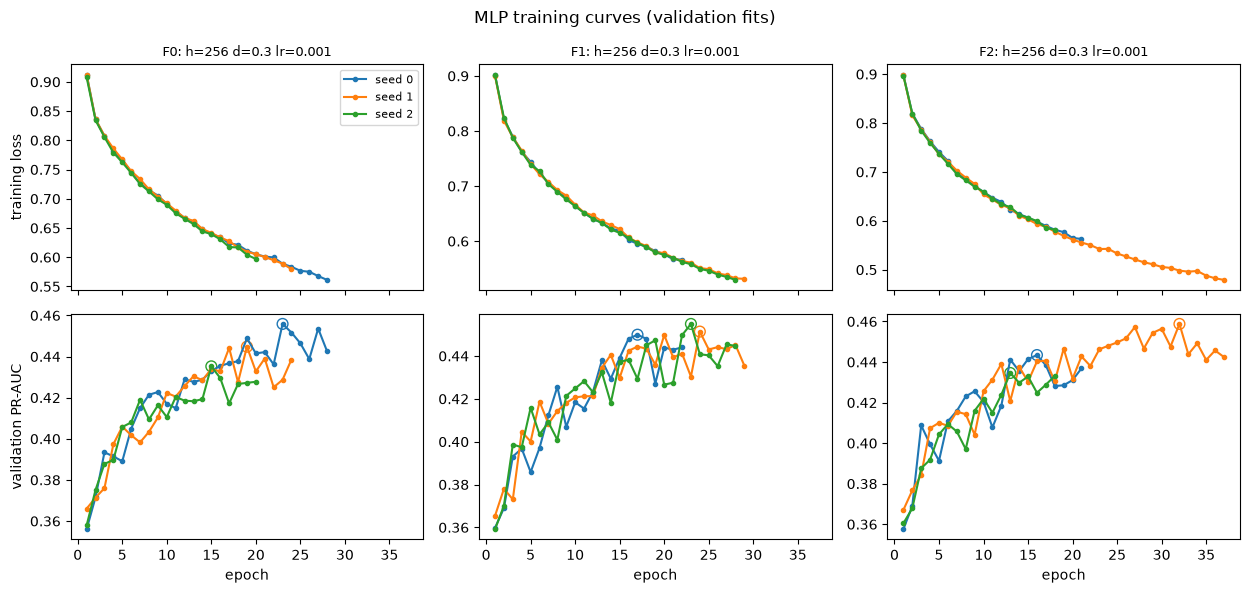

In [6]:
fsets = sorted(val.feature_set.unique())
fig, axes = plt.subplots(2, len(fsets), figsize=(4.2 * len(fsets), 6), sharex=True, squeeze=False)
for j, fs in enumerate(fsets):
    for _, r in val[val.feature_set == fs].sort_values('seed').iterrows():
        f = r['fit']; ep = range(1, f['epochs_run'] + 1)
        line, = axes[0, j].plot(ep, f['loss'], marker='.', label=f"seed {r['seed']}")
        axes[1, j].plot(ep, f['val_pr_auc'], marker='.', color=line.get_color())
        b = f['best_epoch']
        axes[1, j].scatter([b], [f['val_pr_auc'][b - 1]], s=60, facecolors='none', edgecolors=line.get_color())
    axes[0, j].set_title(f'{fs}: {val[val.feature_set == fs].config.iloc[0]}', fontsize=9)
    axes[1, j].set_xlabel('epoch')
axes[0, 0].set_ylabel('training loss'); axes[1, 0].set_ylabel('validation PR-AUC')
axes[0, 0].legend(fontsize=8)
fig.suptitle('MLP training curves (validation fits)'); fig.tight_layout()
fig.savefig(ROOT / 'reports' / 'figures' / 'mlp_training_curves.png', dpi=150)